# ***Lineare Regression 2***
**Methoden der Data Science – Übung, WS 2026/27, Haya Halimeh**

# Einführung
In der letzten Übung haben wir die Grundlagen der linearen Regression kennengelernt und sie auf den [Bikesharing](https://www.kaggle.com/competitions/bike-sharing-demand/)-Datensatz angewendet. Dabei haben wir die Zahl der ausgeliehenen Fahrräder anhand von Wetterdaten vorhergesagt.

In dieser Übung erweitern wir unser Modell um drei Werkzeuge:

1. __Kategoriale Prädiktoren__, z. B. die Jahreszeit
2. __Nichtlineare Transformationen__: polynomiale Terme und die Log-Transformation
3. __Interaktionsterme__

Die Aufgaben in diesem Notebook gehören zu Übungsblatt 5, Aufgabe 2.

In [1]:
import numpy as np
import random
import pandas as pd
from sklearn.model_selection import train_test_split
from statsmodels.formula.api import ols


# Seed für Reproduzierbarkeit setzen
np.random.seed(42)  # Seed für NumPy
random.seed(42) # Seed für das random-Modul

# Daten laden
Zuerst laden wir den Bikesharing-Datensatz.

*Führen Sie den Code unten aus.*

In [2]:
# Daten aus einer CSV-Datei laden
data = pd.read_csv("https://raw.githubusercontent.com/kbrennig/MODS_WS26_27/refs/heads/main/data/BikeSharing.csv")

data.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


# Trainings- und Testdaten erstellen

Wie letzte Woche teilen wir die Daten in 80 % Trainingsdaten und 20 % Testdaten auf.

*Führen Sie den Code unten aus.*

In [3]:
data_training, data_test = train_test_split(data, test_size=0.2, random_state=42)

# Zielvariable: `casual`

In dieser Übung sagen wir nicht __count__ vorher, sondern __casual__. __casual__ ist die Zahl der Ausleihen durch nicht registrierte Personen. Es gilt: __count__ = __casual__ + __registered__.

# Kategoriale Prädiktoren

Am Schätzen des Modells ändert sich im Vergleich zur letzten Woche wenig. Eine kategoriale Variable nehmen wir ins Modell auf, indem wir `C()` um den Prädiktor schreiben. Python erstellt dann automatisch Dummy-Variablen für die Ausprägungen.

Hier sagen wir __casual__ mit __temp__ und der Jahreszeit __season__ vorher und speichern das Modell als `model_01`.

*Führen Sie den Code unten aus.*

In [4]:
# Lineares Regressionsmodell mit temp und der kategorialen Variable season schätzen
model_01 = ols(formula="casual ~ temp + C(season)", data=data_training)
model_01 = model_01.fit()

print(model_01.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                 casual   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.263
No. Observations:                4337   F-statistic:                     387.4
Covariance Type:            nonrobust   Prob (F-statistic):          1.27e-285
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        -25.8250      1.592    -16.224      0.000     -28.946     -22.704
C(season)[T.2]   -11.5818      1.872     -6.187      0.000     -15.252      -7.912
C(season)[T.3]   -19.7048      2.300     -8.568      0.000     -24.214     -15.196
C(season)[T.4]    -3.8368      1.554     -2.468      0.014      -6.884      -0.789
temp               3.2108      0.105     30.454      0.000       3.004       3.418

Notes:
[1] Standard Err

---

# Nichtlineare Zusammenhänge

In vielen realen Daten ist der Zusammenhang zwischen Prädiktor und Zielvariable keine Gerade. Mit Transformationen können wir solche Zusammenhänge trotzdem mit einer linearen Regression abbilden.

## Polynomiale Terme

Eine Möglichkeit, nichtlineare Zusammenhänge abzubilden, sind **polynomiale Terme**. Wir nehmen zusätzlich zu `temp` die Variable `temp²` ins Modell auf.

## **Ihre Aufgabe** (Übungsblatt 5, Aufgabe 2, Teil b)

Erstellen Sie auf den Trainingsdaten das Modell `model_02`. Es sagt `casual` aus `temp` und einem quadrierten Temperaturterm vorher. Geben Sie die Summary aus.

*Tipp: Den quadrierten Term schreiben Sie in der Formel als `I(temp**2)`.*

In [5]:
# Ihr Code hier!

## Log-Transformation

### Daten erkunden

Die Variable __casual__ ist stark rechtsschief: Wenige sehr große Werte ziehen die Verteilung nach rechts.

Schiefe Variablen sind für eine lineare Regression oft schwer zu modellieren. Eine Log-Transformation reduziert die Schiefe: Der Logarithmus staucht große Werte stärker als kleine, die Verteilung wird dadurch symmetrischer.

Das sehen wir am Vergleich der Histogramme vor und nach der Transformation. `np.log()` verwendet den natürlichen Logarithmus (Basis __e__).

*Führen Sie den Code unten aus.*

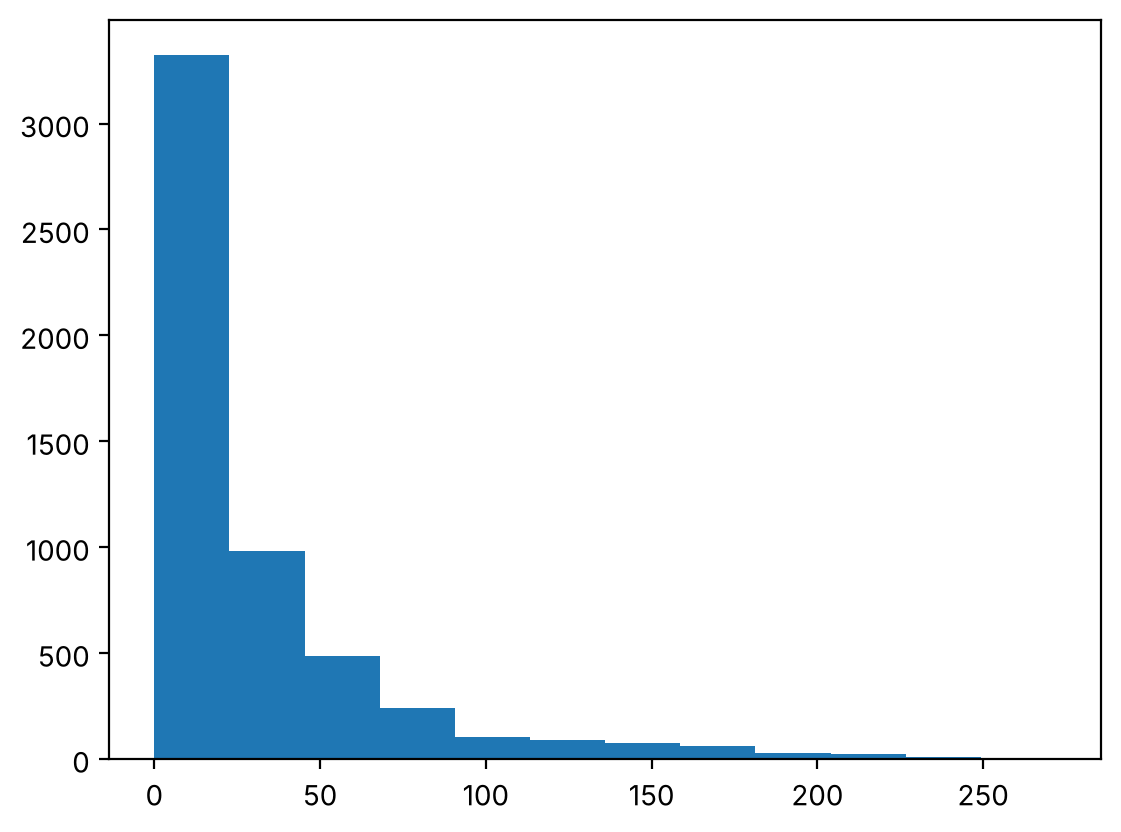

In [6]:
import matplotlib.pyplot as plt

# Histogramm von casual (ohne Transformation)
plt.hist(data["casual"], bins=12)
plt.show()

Jetzt transformieren wir __casual__ mit `np.log(data["casual"]+1)` und schauen uns das Histogramm erneut an.

Warum `+1`? Der Logarithmus von 0 ist nicht definiert. Da __casual__ auch 0 sein kann, addieren wir vorher 1.

*Führen Sie den Code unten aus.*

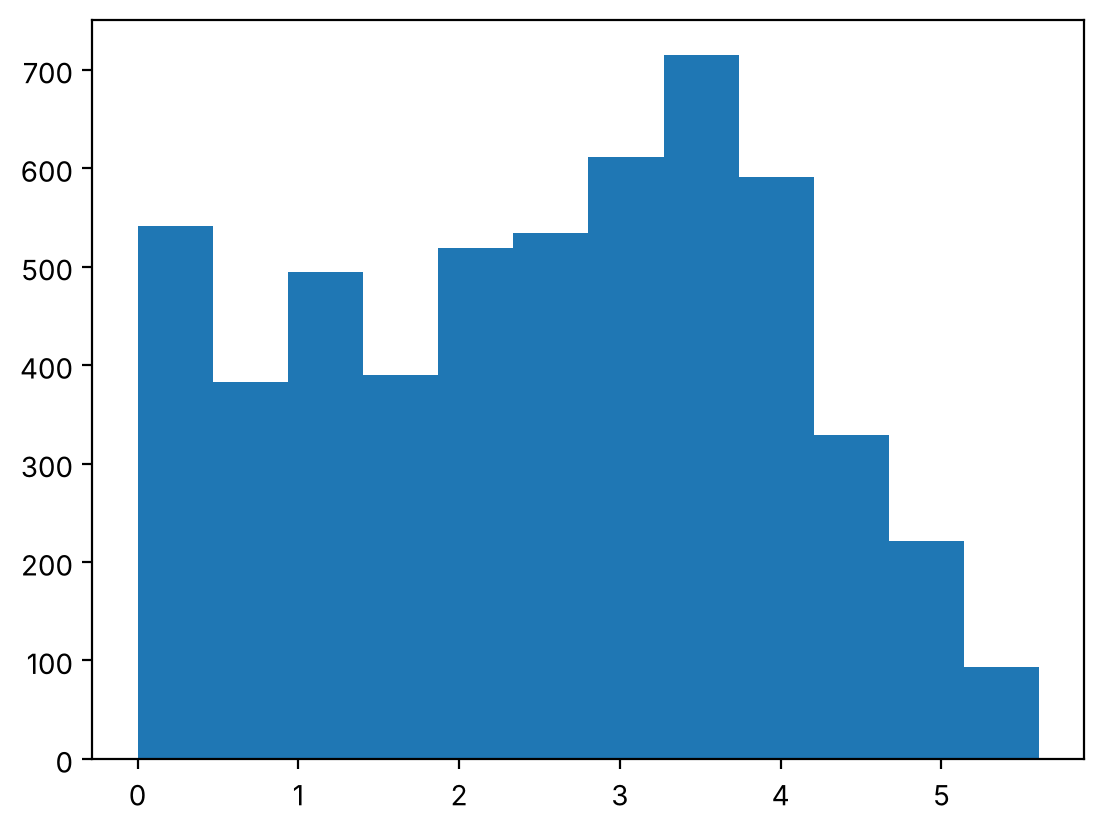

In [7]:
# Histogramm von casual nach der Log-Transformation
plt.hist(np.log(data["casual"]+1), bins=12)
plt.show()

### Zielvariable log-transformieren

Der Code unten:
1. log-transformiert __casual__ und speichert das Ergebnis als neue Spalte __casual_log__ in den Trainingsdaten,
2. schätzt eine lineare Regression mit __casual_log__ als Zielvariable und __temp__ als Prädiktor und speichert sie als `model_03`.

*Führen Sie den Code unten aus.*

In [8]:
# casual log-transformieren und als neue Spalte casual_log speichern
data_training["casual_log"] = np.log(data_training["casual"]+1)
data_training.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,casual_log
2760,2011-07-03 22:00:00,3,0,0,2,27.06,30.305,78,7.0015,69,93,162,4.248495
3817,2011-09-10 01:00:00,3,0,0,2,25.42,27.275,94,0.0000,16,67,83,2.833213
1477,2011-04-07 10:00:00,2,0,1,2,17.22,21.210,67,7.0015,29,66,95,3.401197
75,2011-01-04 07:00:00,1,0,1,1,4.92,7.575,74,8.9981,2,92,94,1.098612
1786,2011-05-01 08:00:00,2,0,0,2,18.04,21.970,77,8.9981,16,43,59,2.833213


In [9]:
# Lineares Regressionsmodell schätzen
model_03 = ols(formula="casual_log ~ temp", data=data_training)
model_03 = model_03.fit()


### Geschätztes Modell ausgeben

Da die Zielvariable log-transformiert ist, liegen auch die Koeffizienten auf der log-Skala. Am Koeffizienten von __temp__ können wir deshalb die __Richtung__ des Effekts ablesen (positiv oder negativ), aber __nicht direkt die Höhe__ in Fahrrädern.

*Führen Sie den Code unten aus.*

In [10]:
# Summary von model_03 ausgeben
print(model_03.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:             casual_log   R-squared:                       0.353
Model:                            OLS   Adj. R-squared:                  0.353
No. Observations:                4337   F-statistic:                     2363.
Covariance Type:            nonrobust   Prob (F-statistic):               0.00
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.4245      0.047      9.020      0.000       0.332       0.517
temp           0.1073      0.002     48.612      0.000       0.103       0.112

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


---

# Interaktionsterme

Mit einem Interaktionsterm kann der Effekt eines Prädiktors vom Wert eines anderen Prädiktors abhängen. Ein Beispiel: Ein zusätzliches Grad Temperatur bringt bei hoher Luftfeuchtigkeit vielleicht weniger zusätzliche Ausleihen als bei trockenem Wetter.

## **Ihre Aufgabe** (Übungsblatt 5, Aufgabe 2, Teil d)

Erstellen Sie auf den Trainingsdaten das Modell `model_04`. Es sagt `casual` aus `temp`, `humidity` und ihrer Interaktion vorher. Geben Sie die Summary aus.

*Tipp: Die Interaktion schreiben Sie in der Formel als `temp:humidity`.*

In [11]:
# Ihr Code hier!

# Zusammenfassung

Was haben wir in dieser Übung gemacht?

1. Wir haben __kategoriale Prädiktoren__ mit `C()` ins Modell aufgenommen.
2. Wir haben mit __polynomialen Termen__ einen gekrümmten Zusammenhang modelliert.
3. Wir haben eine schiefe Zielvariable __log-transformiert__.
4. Wir haben mit einem __Interaktionsterm__ modelliert, dass der Effekt eines Prädiktors von einem anderen abhängt.